In [7]:
import torch
import math
from torch.distributions.multivariate_normal import MultivariateNormal
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

In [19]:
import torch
import math

def make_kgrid_2d(Nx, Ny, Lx=2*math.pi, Ly=2*math.pi, device="cpu", dtype=torch.float32):
    kx = 2*math.pi*torch.fft.fftfreq(Nx, d=Lx/Nx, device=device).to(dtype)
    ky = 2*math.pi*torch.fft.fftfreq(Ny, d=Ly/Ny, device=device).to(dtype)
    KX, KY = torch.meshgrid(kx, ky, indexing="ij")  # (Nx,Ny)
    K2 = KX**2 + KY**2
    return KX, KY, K2

def dealias_mask_2d(Nx, Ny, device="cpu", ctype=torch.complex64):
    # 2/3-rule cutoff in frequency index space
    fx = torch.fft.fftfreq(Nx, d=1.0, device=device).abs()
    fy = torch.fft.fftfreq(Ny, d=1.0, device=device).abs()
    FX, FY = torch.meshgrid(fx, fy, indexing="ij")
    mask = ((FX <= (Nx//3)/Nx) & (FY <= (Ny//3)/Ny)).to(ctype)
    return mask

@torch.no_grad()
def smooth_random_vorticity_ic(B, Nx, Ny, kmax=8, amp=1.0, device="cpu", dtype=torch.float32):
    """
    Smooth random initial vorticity: band-limited random Fourier coefficients up to |k|<=kmax.
    Returns omega0: (B,Nx,Ny) real
    """
    ctype = torch.complex64 if dtype == torch.float32 else torch.complex128
    # random complex Fourier coefficients
    w_hat = torch.zeros(B, Nx, Ny, device=device, dtype=ctype)
    kx = torch.fft.fftfreq(Nx, d=1.0, device=device) * Nx
    ky = torch.fft.fftfreq(Ny, d=1.0, device=device) * Ny
    KX, KY = torch.meshgrid(kx, ky, indexing="ij")
    Kabs = torch.sqrt(KX**2 + KY**2)

    band = (Kabs <= kmax)
    # random complex values in the band
    re = torch.randn(B, Nx, Ny, device=device, dtype=dtype)
    im = torch.randn(B, Nx, Ny, device=device, dtype=dtype)
    rnd = (re + 1j*im).to(ctype)

    # spectral decay to make it smooth
    decay = (1.0 / (1.0 + Kabs**2)).to(dtype)
    decay = decay / decay.max()

    w_hat[:, band] = (amp * decay[band]).to(ctype) * rnd[:, band]

    # enforce Hermitian symmetry for real field is automatically satisfied if we generate via ifft of arbitrary complex?
    # Not guaranteed; easiest is: generate real field in physical space by taking real part after ifft.
    omega0 = torch.fft.ifft2(w_hat, dim=(-2, -1)).real
    omega0 = omega0 - omega0.mean(dim=(-2, -1), keepdim=True)  # zero mean vorticity
    return omega0.to(dtype)

@torch.no_grad()
def make_forcing_hat(Nx, Ny, KX, KY, kind="kolmogorov", amp=1.0, device="cpu", dtype=torch.float32):
    """
    Returns f_hat: (Nx,Ny) complex forcing in vorticity equation.
    kind="kolmogorov": f_omega = amp * sin(k_f y)  (acts directly on vorticity)
    In Fourier, this is nonzero at ky=±k_f.
    """
    ctype = torch.complex64 if dtype == torch.float32 else torch.complex128
    f_hat = torch.zeros(Nx, Ny, device=device, dtype=ctype)
    if kind is None:
        return f_hat

    if kind == "kolmogorov":
        kf = 4  # forcing wavenumber (integer mode)
        # sin(kf y) -> Fourier modes at ky=±kf with imaginary coefficients
        # In continuous Fourier: sin(k y) = (e^{iky}-e^{-iky})/(2i)
        # Here KY grid is 2π * integer / Ly, but using FFT convention indices.
        # We'll place forcing at ky index corresponding to +kf and -kf.
        ky_idx_pos = kf % Ny
        ky_idx_neg = (-kf) % Ny
        # Put forcing in physical space is easiest, then FFT it:
        y = torch.linspace(0, 2*math.pi, Ny, device=device, dtype=dtype, requires_grad=False)
        f_phys = amp * torch.sin(kf * y)[None, :].repeat(Nx, 1)  # (Nx,Ny)
        f_hat = torch.fft.fft2(f_phys.to(dtype), dim=(-2, -1)).to(ctype)
        return f_hat

    raise ValueError(f"Unknown forcing kind: {kind}")

@torch.no_grad()
def vorticity_to_velocity_hat(omega_hat, KX, KY, K2, eps=1e-12):
    """
    omega_hat: (B,Nx,Ny) complex
    Returns u_hat, v_hat (B,Nx,Ny) complex
    u = dpsi/dy, v = -dpsi/dx, with psi_hat = -omega_hat / K2 (since omega = -K2 psi in Fourier)
    """
    # psi_hat = - omega_hat / K2, but K2=0 at mean -> set psi_hat(0)=0
    K2_safe = K2.clone()
    K2_safe[0, 0] = 1.0
    psi_hat = -omega_hat / K2_safe[None, :, :]
    psi_hat[:, 0, 0] = 0.0 + 0.0j

    u_hat = 1j * KY[None, :, :].to(omega_hat.dtype) * psi_hat
    v_hat = -1j * KX[None, :, :].to(omega_hat.dtype) * psi_hat
    return u_hat, v_hat

@torch.no_grad()
def nonlinear_term_hat(omega_hat, KX, KY, K2, dealias_mask):
    """
    Compute N_hat = - FFT( u * omega_x + v * omega_y )
    """
    u_hat, v_hat = vorticity_to_velocity_hat(omega_hat, KX, KY, K2)

    # omega_x_hat = i kx omega_hat, omega_y_hat = i ky omega_hat
    omega_x_hat = 1j * KX[None, :, :].to(omega_hat.dtype) * omega_hat
    omega_y_hat = 1j * KY[None, :, :].to(omega_hat.dtype) * omega_hat

    # go to physical space
    u = torch.fft.ifft2(u_hat, dim=(-2, -1)).real
    v = torch.fft.ifft2(v_hat, dim=(-2, -1)).real
    omega_x = torch.fft.ifft2(omega_x_hat, dim=(-2, -1)).real
    omega_y = torch.fft.ifft2(omega_y_hat, dim=(-2, -1)).real

    adv = u * omega_x + v * omega_y                       # (B,Nx,Ny) real
    adv_hat = torch.fft.fft2(adv, dim=(-2, -1))            # complex
    adv_hat = adv_hat * dealias_mask[None, :, :]           # de-alias
    return -adv_hat

@torch.no_grad()
def integrate_ns2d_vorticity(
    omega0,
    nu=1e-3,
    dt=0.01,
    steps=2000,
    save_every=10,
    forcing_kind="kolmogorov",
    forcing_amp=0.1,
    Lx=2*math.pi,
    Ly=2*math.pi,
    dealias=True,
):
    """
    omega0: (B,Nx,Ny) real
    returns traj_flat: (Tsave,B,Nx*Ny) real
    """
    device = omega0.device
    dtype = omega0.dtype
    ctype = torch.complex64 if dtype == torch.float32 else torch.complex128

    B, Nx, Ny = omega0.shape
    KX, KY, K2 = make_kgrid_2d(Nx, Ny, Lx=Lx, Ly=Ly, device=device, dtype=dtype)
    K2_c = K2.to(dtype)
    mask = dealias_mask_2d(Nx, Ny, device=device, ctype=ctype) if dealias else torch.ones(Nx, Ny, device=device, dtype=ctype)

    # linear operator in Fourier: nu * (-K2)
    Lop = (-nu * K2).to(ctype)  # (Nx,Ny) complex

    # integrating factor
    E = torch.exp(dt * Lop)  # (Nx,Ny)
    E_half = torch.exp(0.5 * dt * Lop)

    # forcing in Fourier (time-independent here)
    f_hat = make_forcing_hat(Nx, Ny, KX, KY, kind=forcing_kind, amp=forcing_amp, device=device, dtype=dtype).to(ctype)
    f_hat = f_hat * mask  # dealias forcing too

    omega_hat = torch.fft.fft2(omega0, dim=(-2, -1)).to(ctype) * mask[None, :, :]

    Tsave = steps // save_every + 1
    traj = torch.empty(Tsave, B, Nx, Ny, device=device, dtype=dtype)
    traj[0] = omega0
    si = 1

    def step_rhs(omega_hat_local):
        return nonlinear_term_hat(omega_hat_local, KX, KY, K2_c, mask) + f_hat[None, :, :]

    # Integrating factor RK4:
    # Let v = exp(-tL) omega_hat. Then v' = exp(-tL) (N(omega_hat)+f)
    # We implement one RK4 step in v, using omega_hat = exp(tL)v.
    for n in range(1, steps + 1):
        # current v
        # we don't explicitly store t; use omega_hat and update with IF-RK4
        Nv1 = step_rhs(omega_hat) * 1.0

        a = E_half[None, :, :] * (omega_hat + 0.5 * dt * Nv1)
        Nv2 = step_rhs(a)

        b = E_half[None, :, :] * (omega_hat + 0.5 * dt * Nv2)
        Nv3 = step_rhs(b)

        c = E[None, :, :] * (omega_hat + dt * Nv3)
        Nv4 = step_rhs(c)

        omega_hat = E[None, :, :] * omega_hat + (dt / 6.0) * (E[None, :, :] * Nv1 + 2*E_half[None, :, :]*Nv2 + 2*E_half[None, :, :]*Nv3 + Nv4)
        omega_hat = omega_hat * mask[None, :, :]

        if n % save_every == 0:
            omega = torch.fft.ifft2(omega_hat, dim=(-2, -1)).real
            traj[si] = omega
            si += 1

    traj_flat = traj.reshape(Tsave, B, Nx * Ny)
    return traj_flat

In [20]:
device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float32

B = 32
Nx = Ny = 64

omega0 = smooth_random_vorticity_ic(B, Nx, Ny, kmax=8, amp=5.0, device=device, dtype=dtype)

traj_flat = integrate_ns2d_vorticity(
    omega0,
    nu=1e-3,
    dt=0.01,
    steps=5000,
    save_every=10,
    forcing_kind="kolmogorov",  # or None
    forcing_amp=0.1,
    dealias=True
)

print(traj_flat.shape)  # (Tsave, B, Nx*Ny)

torch.Size([501, 32, 4096])


In [380]:
T = traj_flat.shape[0]
horizon = 5
L = 10
gamma = 0.95
slicing = 20
# traj_flat: (T,B,Nx*Ny)
p = 256  # number of sensors
Nstate = Nx*Ny
idx_gen = torch.linspace(0, Nstate-1, p).long().to(traj_flat.device)  # evenly spaced sensors
traj_obs = traj_flat[:, :, idx_gen]  # (T,B,p)

Hmax = horizon  # or 50
t0 = L - 1
t1 = T - 1 - Hmax
t_vals = list(range(t0, t1+1))
n_t = len(t_vals)


# standardize observations (inputs only), using TRAIN trajectories ideally
mu = traj_obs.mean(dim=(0,1), keepdim=True)   # (1,1,p)
sd = traj_obs.std(dim=(0,1), keepdim=True) + 1e-6
obs_std = (traj_obs - mu) / sd                # (T,B,p)


# lag weights, most recent first: [w0 for o_t, w1 for o_{t-1}, ...]
w = (gamma ** torch.arange(L, device=traj_obs.device, dtype=traj_obs.dtype))  # (L,)

Y = torch.empty(B, n_t, p,   device=traj_obs.device, dtype=traj_obs.dtype)

U = torch.empty(B, n_t, p*L, device=traj_obs.device, dtype=traj_obs.dtype)
for j in range(B):
    for i, t in enumerate(t_vals):
        window = obs_std[t-L+1:t+1, j, :]        # (L,p)
        window = torch.flip(window, dims=[0])    # newest->oldest
        window = window * w[:, None]
        U[j, i, :] = window.reshape(-1)

# flatten across trajectories/time
U_flat = U.reshape(B*n_t, p*L)
Y_flat = Y.reshape(B*n_t, p)
sample_size = 30000
idx = torch.randperm(U_flat.shape[0], device=U_flat.device)[:sample_size]
U_train = U_flat[idx]
Y_train_raw = Y_flat[idx]

Y_mean = Y_flat.mean(dim=0, keepdim=True)
Y_std  = Y_flat.std(dim=0, keepdim=True) + 1e-6

Y_train = (Y_train_raw - Y_mean) / Y_std

In [381]:
def phi(u, Omega, b, sigma=1.0, P=512):
    # u: (d_u,)
    z = math.sqrt(2.0 / P) * torch.cos(Omega @ u + b)  # (P,)
    return torch.cat([u, sigma * z], dim=0)            # (d_u+P,)

def solve_W(U, Y, Omega, b, sigma=1.0, P=512, lam=1.0):
    # U: (n, d_u), Y: (n, p_out)
    n, d_u = U.shape
    p_out = Y.shape[1]
    d = d_u + P

    G = torch.zeros(d, d, device=U.device, dtype=U.dtype)
    H = torch.zeros(d, p_out, device=U.device, dtype=U.dtype)

    for i in range(n):
        phi_i = phi(U[i], Omega, b, sigma, P)              # (d,)
        G += torch.outer(phi_i, phi_i)                     # (d,d)
        H += torch.outer(phi_i, Y[i])                      # (d,p_out)
    G /= n
    H /= n

    W = torch.linalg.solve(G + lam * torch.eye(d, device=U.device, dtype=U.dtype), H)  # (d,p_out)
    return W

def horizon_forecast(test_traj, Omega, b, sigma, p, P, W,
                     U_mean, U_std, Y_mean, Y_std, L, horizon=10):
    T = test_traj.shape[0]
    n_t = T - horizon - L + 1

    test_std = (test_traj - U_mean) / U_std
    preds = torch.empty(n_t, p, device=test_traj.device, dtype=test_traj.dtype)

    for t in range(n_t):
        window = test_std[t:t+L, :]                    # (L,p), oldest->newest
        window = torch.flip(window, dims=[0])          # newest->oldest
        u_t = window.reshape(-1)                       # (pL,)
        do_std = phi(u_t, Omega, b, sigma, P) @ W      # (p,)
        do = Y_mean + Y_std * do_std                   # (p,)
        o_t = test_traj[t+L-1, :]                      # current obs in original space
        preds[t, :] = o_t + do                         # forecast o_{t+h}
    return preds

def model_mse(y_true, y_pred):
    return ((y_true - y_pred)**2).mean()

In [382]:
M = U_train.shape[0]
idx1 = torch.randint(0, M, (sample_size,), device=U_train.device)
idx2 = torch.randint(0, M, (sample_size,), device=U_train.device)
d = torch.linalg.norm(U_train[idx1] - U_train[idx2], dim=1)
ell = d.median()
sigma = 1
P = 512
#P = 0
mvn = MultivariateNormal(torch.zeros(U_train.shape[1]),ell**-2*torch.eye(U_train.shape[1]))
Omega = torch.randn(P, U_train.shape[1], device=device, dtype=U_train.dtype) / ell
b = (2*torch.pi*torch.rand((P,), device=device, dtype=U_train.dtype))

W = solve_W(U_train, Y_train, Omega, b, sigma=1.0, P=P, lam=10**1)


In [383]:

# KS example
B_test = 1
# u0 = ic_low_mode_random(B_test, N, L=22.0, n_modes=8, amp=2.0, device=device)
# traj_test = integrate_ks_etdrk4(u0, L=22.0, dt=0.0025, steps=4000, save_every=10)  # (T,B,N)

omega0_test = smooth_random_vorticity_ic(B_test, Nx, Ny, kmax=8, amp=5.0, device=device, dtype=dtype)

traj_flat_test = integrate_ns2d_vorticity(
    omega0_test,
    nu=1e-3,
    dt=0.01,
    steps=5000,
    save_every=10,
    forcing_kind="kolmogorov",  # or None
    forcing_amp=0.1,
    dealias=True
)

traj_test_obs = traj_flat_test[:, :, idx_gen]

In [384]:
traj_pred = horizon_forecast(
    traj_test_obs[:,0,:],   # (T,p)
    Omega, b, sigma, p, P, W,
    mu.squeeze(0).squeeze(0), sd.squeeze(0).squeeze(0),
    Y_mean, Y_std, L,
    horizon=horizon
)

In [385]:
# T = traj_test_obs.shape[0]
# n_t = T - horizon - L + 1

y_pred = traj_pred                                    # (n_t,p)
y_true = traj_test_obs[L-1+horizon : L-1+horizon+n_t, 0, :]  # (n_t,p)

mse = ((y_true - y_pred)**2).mean()

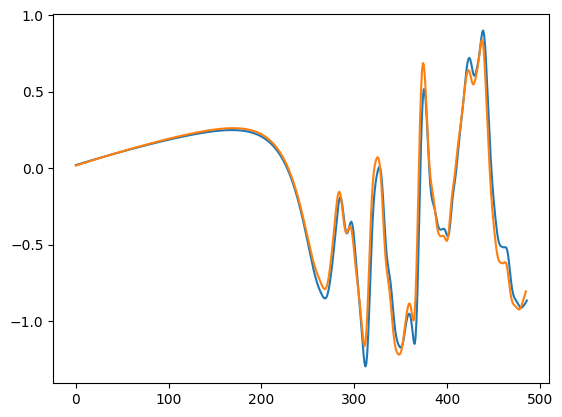

In [386]:
plt.plot(traj_pred[:,2])
plt.plot(traj_test_obs[L:-horizon,0,2])

In [387]:
k = 2000
U_all = U.reshape(B*n_t, p*L).detach().cpu().numpy()
pca = PCA(n_components=k)
       # (B*n_t, k)
S_all = pca.fit_transform(U_all)                      # (B*n_t,k)
S_seq = torch.tensor(S_all, device=U.device, dtype=U.dtype).reshape(B, n_t, k)

mu_u = torch.tensor(pca.mean_, device=U.device, dtype=U.dtype)           # (d_u,)
V_k  = torch.tensor(pca.components_, device=U.device, dtype=U.dtype)     # (k, d_u)

# 2) reshape latent sequence
S_seq = torch.tensor(S_all, device=U.device, dtype=U.dtype).reshape(B, n_t, k)

# 3) build pairs
S_flat      = S_seq[:, :-1, :].reshape(B*(n_t-1), k)
S_next_flat = S_seq[:, 1:,  :].reshape(B*(n_t-1), k)

# 4) ridge solve for A
beta = 1e-5
G = S_flat.T @ S_flat
H = S_flat.T @ S_next_flat
A_T = torch.linalg.solve(G + beta*torch.eye(k, device=U.device, dtype=U.dtype), H)
A = A_T.T

In [388]:
traj_test_obs = traj_flat_test[:, :, idx_gen]

o = traj_test_obs[:, 0, :]             # (T, p)
o_std = (o - mu.squeeze(0).squeeze(0)) / sd.squeeze(0).squeeze(0)   # (T,p)

In [389]:
T = o.shape[0]

t0 = L - 1
t1 = T - 1 - horizon          # IMPORTANT
t_vals = list(range(t0, t1 + 1))
n_t = len(t_vals)

U_test = torch.empty(n_t, p*L, device=o.device, dtype=o.dtype)
for i, t in enumerate(t_vals):
    window = o_std[t-L+1:t+1, :]
    window = torch.flip(window, dims=[0])
    window = window * w[:, None]
    U_test[i, :] = window.reshape(-1)

S_test = (U_test - mu_u) @ V_k.T

A10 = torch.matrix_power(A, horizon)
S10_pred = S_test @ A10.T
U10_pred = mu_u + (S10_pred @ V_k)
o10_pred_std = U10_pred[:, :p]
mu_obs = mu.squeeze(0).squeeze(0)   # (p,)
sd_obs = sd.squeeze(0).squeeze(0)   # (p,)
o10_pred = mu_obs + sd_obs * o10_pred_std


t_tensor = torch.tensor(t_vals, device=o.device)
o_true_h = o[t_tensor + horizon, :]      # now always in-bounds
o_pers   = o[t_tensor, :]
mse      = ((o10_pred - o_true_h)**2).mean()
pers_mse = ((o_pers   - o_true_h)**2).mean()

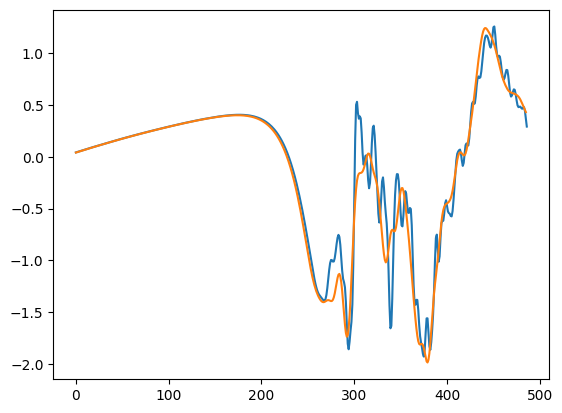

In [390]:
plt.plot(o10_pred[:,7])
plt.plot(traj_test_obs[L+horizon:,0,7])

In [391]:
S = S_seq[:, :-1, :].reshape(-1, k)

traj_obs = traj_flat[:, :, idx_gen]                    # (T,B,p)

S0   = S_seq[:, :-horizon, :].reshape(-1, k)
dS_h = (S_seq[:, horizon:, :] - S_seq[:, :-horizon, :]).reshape(-1, k)


# standardize observations (inputs only), using TRAIN trajectories ideally
mu = traj_obs.mean(dim=(0,1), keepdim=True)   # (1,1,p)
sd = traj_obs.std(dim=(0,1), keepdim=True) + 1e-6
obs_std = (traj_obs - mu) / sd                # (T,B,p)


S_train = S0.reshape(-1, k)           # (B*(n_t-h), k)


O_seq = obs_std[t_vals, :, :]          # (n_t, B, p)
O_seq = O_seq.permute(1, 0, 2)         # (B, n_t, p)  to match S_seq shape
O = O_seq[:, :-1, :].reshape(-1, p)    # (B*(n_t-1), p)

In [392]:
M = S.shape[0]
idx1 = torch.randint(0, M, (sample_size,), device=S.device)
idx2 = torch.randint(0, M, (sample_size,), device=S.device)
d = torch.linalg.norm(S[idx1] - S[idx2], dim=1)
ell = d.median()
sigma = 1
P = 512
mvn = MultivariateNormal(torch.zeros(S.shape[1]),ell**-2*torch.eye(S.shape[1]))
Omega = torch.randn(P, S.shape[1], device=S.device, dtype=U_train.dtype) / ell
b = (2*torch.pi*torch.rand((P,), device=S.device, dtype=U_train.dtype))

In [393]:
p

256

In [394]:
def build_W_f(S_train, dS, Omega, b,sigma = 1.0,P=512, lam=10**3):
        # U: (n, d_u), Y: (n, p_out)
    n, d_u = S_train.shape
    p_out = dS.shape[1]
    d = d_u + P

    G = torch.zeros(d, d, device=S_train.device, dtype=S_train.dtype)
    H = torch.zeros(d, p_out, device=S_train.device, dtype=S_train.dtype)

    for i in range(n):
        phi_i = phi(S_train[i], Omega, b, sigma, P)# (d,)
        G += torch.outer(phi_i, phi_i)                     # (d,d)
        H += torch.outer(phi_i, dS[i])                      # (d,p_out)
    G /= n
    H /= n

    W = torch.linalg.solve(G + lam * torch.eye(d, device=S_train.device, dtype=S_train.dtype), H)  # (d,p_out)
    
    return W

def build_C_tilde(S_train, O, lam=10**3):
    # U: (n, d_u), Y: (n, p_out)
    n, d_u = S_train.shape
    p_out = O.shape[1]
    d = d_u+1
    

    G = torch.zeros(d, d, device=S_train.device, dtype=S_train.dtype)
    H = torch.zeros(d, p_out, device=S_train.device, dtype=S_train.dtype)

    for i in range(n):
        one = torch.ones(1, device=S_train.device, dtype=S_train.dtype)
        phi_i = torch.cat([S_train[i], one])
        G += torch.outer(phi_i, phi_i)                     # (d,d)
        H += torch.outer(phi_i, O[i])                      # (d,p_out)
    G /= n
    H /= n

    C_tilde = torch.linalg.solve(G + lam * torch.eye(d, device=S_train.device, dtype=S_train.dtype), H)  # (d,p_out)
    
    return C_tilde

In [420]:
lam_f = 10**8
lam_g = 10**-5

W_h = build_W_f(S_train,dS_h,Omega,b,sigma=1.0,P=P,lam=lam_f)

In [421]:
O_seq = obs_std[t_vals, :, :].permute(1,0,2)   # (B,n_t,p)
O0 = O_seq[:, :-horizon, :].reshape(-1, p)           # aligns with S0

C_tilde = build_C_tilde(S0, O0, lam=lam_g)
C = C_tilde[:-1, :]
d = C_tilde[-1, :]

In [422]:
o = traj_test_obs[:,0,:]         # (T_test,p)
T_test = o.shape[0]
t0 = L - 1
t1 = T_test - 1 - horizon
t_vals_test = list(range(t0, t1+1))
n_test = len(t_vals_test)
U_test = torch.empty(n_test, p*L, device=o.device, dtype=o.dtype)
for i, t in enumerate(t_vals_test):
    window = o_std[t-L+1:t+1, :]         # (L,p)
    window = torch.flip(window, dims=[0])
    window = window * w[:, None]
    U_test[i,:] = window.reshape(-1)

S_test = (U_test - mu_u) @ V_k.T         # (n_test,k)

In [423]:
def phi_batch(S, Omega, b, sigma=1.0, P=512):
    # S: (n,k), Omega: (P,k), b: (P,)
    Z = (Omega @ S.T).T + b           # (n,P)
    z = (2.0/P)**0.5 * torch.cos(Z)   # (n,P)
    return torch.cat([S, sigma*z], dim=1)  # (n,k+P

Phi0 = phi_batch(S_test, Omega, b, sigma, P)
dS_pred = Phi0 @ W_h
S_pred = S_test + dS_pred


o_pred_std = S_pred @ C + d              # (n_test,p)
o_pred = mu_obs + sd_obs * o_pred_std

t_tensor = torch.tensor(t_vals_test, device=o.device)
o_true = o[t_tensor + horizon, :]

o_pers = o[t_tensor, :]

mse = ((o_pred - o_true)**2).mean()
pers_mse = ((o_pers - o_true)**2).mean()

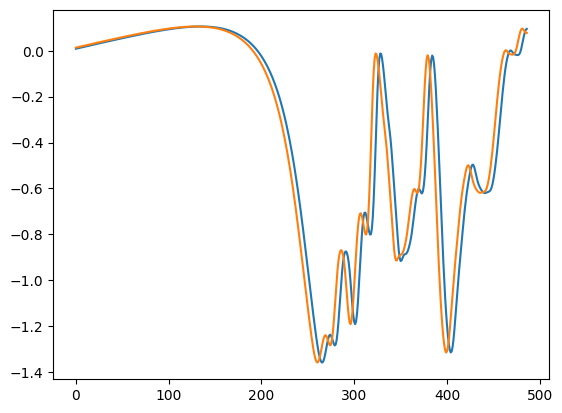

In [424]:
plt.plot(o_pred[:,5])
plt.plot(o_true[:,5])

In [425]:
def standardize_fit(X, eps=1e-6):
    """
    X: (n, d)
    returns: Xs, mean (1,d), std (1,d)
    """
    mean = X.mean(dim=0, keepdim=True)
    std  = X.std(dim=0, keepdim=True) + eps
    Xs = (X - mean) / std
    return Xs, mean, std

def standardize_apply(X, mean, std):
    return (X - mean) / std

def unstandardize_apply(Xs, mean, std):
    return Xs * std + mean

def phi_batch(S, Omega, b, sigma=1.0):
    """
    S: (n,k)
    Omega: (P,k)
    b: (P,)
    Returns: (n, k+P) = [S, sigma*z]
    """
    n, k = S.shape
    P = Omega.shape[0]
    Z = (S @ Omega.T) + b   # (n,P)
    z = math.sqrt(2.0 / P) * torch.cos(Z)
    return torch.cat([S, sigma*z], dim=1)

def build_W_rff_ridge(S_in, Y_out, Omega, b, sigma=1.0, lam=1e-4):
    """
    S_in: (n,k) inputs
    Y_out: (n,k_out) targets
    W: (k+P, k_out)
    """
    Phi = phi_batch(S_in, Omega, b, sigma=sigma)  # (n, k+P)
    n = Phi.shape[0]
    G = (Phi.T @ Phi) / n
    H = (Phi.T @ Y_out) / n
    d = G.shape[0]
    W = torch.linalg.solve(G + lam*torch.eye(d, device=G.device, dtype=G.dtype), H)
    return W



def predict_direct_horizon_latent(S0, W_h, Omega, b, sigma=1.0):
    """
    S0: (n,k) (already standardized if that's what you trained on)
    returns dS_pred: (n,k)
    """
    Phi0 = phi_batch(S0, Omega, b, sigma=sigma)  # (n, k+P)
    return Phi0 @ W_h

In [426]:

# Standardize inputs and targets
S0s, S_mean, S_std = standardize_fit(S0)
dS_s, dS_mean, dS_std = standardize_fit(dS_h)

# Choose ell and sample Omega,b based on STANDARDIZED inputs
# (you can keep your median heuristic here)
# Omega: (P,k)
# b: (P,)

W_h = build_W_rff_ridge(S0s, dS_s, Omega, b, sigma=1.0, lam=lam_f)

# 1) standardize input latents using TRAIN stats
S_test0s = standardize_apply(S_test, S_mean, S_std)

# 2) predict standardized latent increment
dS_pred_s = predict_direct_horizon_latent(S_test0s, W_h, Omega, b, sigma=1.0)

# 3) unstandardize increment back to latent units
dS_pred = unstandardize_apply(dS_pred_s, dS_mean, dS_std)

# 4) form predicted latent at horizon
S_pred_h = S_test + dS_pred


o_pred_std = S_pred_h @ C + d              # (n_test,p)
o_pred = mu_obs + sd_obs * o_pred_std

t_tensor = torch.tensor(t_vals_test, device=o.device)
o_true = o[t_tensor + horizon, :]

o_pers = o[t_tensor, :]

mse = ((o_pred - o_true)**2).mean()
pers_mse = ((o_pers - o_true)**2).mean()

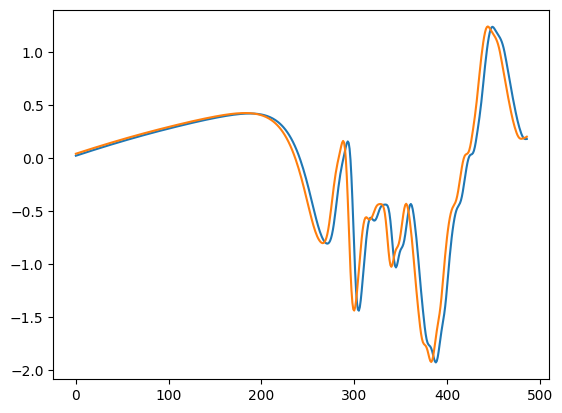

In [427]:
plt.plot(o_pred[:,3])
plt.plot(o_true[:,3])

In [428]:
O_seq = obs_std[t_vals, :, :].permute(1,0,2)     # (B, n_t, p)
S_dec = S_seq.reshape(B*n_t, k)                  # (B*n_t, k)
O_dec = O_seq.reshape(B*n_t, p)                  # (B*n_t, p)

In [429]:
def median_ell(X, sample_size=5000):
    n = X.shape[0]
    idx1 = torch.randint(0, n, (sample_size,), device=X.device)
    idx2 = torch.randint(0, n, (sample_size,), device=X.device)
    d = torch.linalg.norm(X[idx1] - X[idx2], dim=1)
    return d.median()

# optional: standardize S_dec before choosing ell
S_mean = S_dec.mean(dim=0, keepdim=True)
S_std  = S_dec.std(dim=0, keepdim=True) + 1e-6
S_dec_s = (S_dec - S_mean) / S_std

ell_o = median_ell(S_dec_s)
P_o = 512
Omega_o = torch.randn(P_o, k, device=S_dec.device, dtype=S_dec.dtype) / ell_o
b_o = 2*torch.pi*torch.rand(P_o, device=S_dec.device, dtype=S_dec.dtype)

In [430]:
def psi_batch(S, Omega, b, sigma=1.0):
    # S: (n,k), Omega: (P,k), b: (P,)
    n, k = S.shape
    P = Omega.shape[0]
    Z = S @ Omega.T + b              # (n,P)
    z = math.sqrt(2.0 / P) * torch.cos(Z)
    return torch.cat([S, sigma*z], dim=1)   # (n, k+P)

def fit_rff_ridge(X_feat, Y, lam=1e-4):
    # X_feat: (n,d), Y: (n,p_out)
    n = X_feat.shape[0]
    G = (X_feat.T @ X_feat) / n
    H = (X_feat.T @ Y) / n
    d = G.shape[0]
    W = torch.linalg.solve(G + lam*torch.eye(d, device=G.device, dtype=G.dtype), H)
    return W

In [431]:
Psi = psi_batch(S_dec_s, Omega_o, b_o, sigma=1.0)  # (n, k+P_o)
W_o = fit_rff_ridge(Psi, O_dec, lam=lam_g)         # (k+P_o, p)

In [432]:
S_pred_s = (S_pred_h - S_mean) / S_std
o_pred_std = psi_batch(S_pred_s, Omega_o, b_o, sigma=1.0) @ W_o   # (n_test, p)

o_pred = mu_obs + sd_obs * o_pred_std


mse = ((o_pred - o_true)**2).mean()
pers_mse = ((o_pers - o_true)**2).mean()

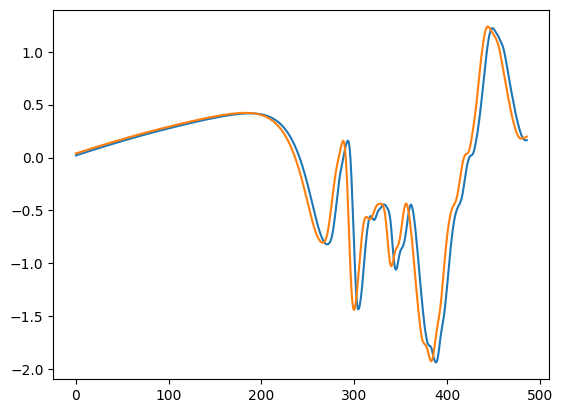

In [433]:
plt.plot(o_pred[:,3])
plt.plot(o_true[:,3])